# Notebook 2: Data Cleaning and Preprocessing

## Project
Exploratory Data Analysis of NIFTY 50 Futures and Options Market

## 1. Introduction

This notebook focuses on cleaning and preprocessing the historical NIFTY 50 Futures and Options datasets obtained from the National Stock Exchange (NSE).

Building upon the data understanding and quality assessment performed in Notebook 1, this stage addresses data type conversion, missing-value handling, duplicate investigation, date standardization, and data validation.

The notebook processes three datasets independently:

1. Futures
2. Call Options (CE)
3. Put Options (PE)

The original raw datasets are preserved without modification. All preprocessing operations are performed on separate working DataFrames, and the resulting datasets are stored in the data/processed directory.

### Study Period

1 January 2021 to 25 September 2026.

September 2026 represents partial-month coverage and must be treated accordingly during subsequent analysis.

### Objectives

- Standardize column names across quarterly files.
- Convert date and numerical fields into appropriate data types.
- Investigate and handle placeholder values.
- Examine and resolve verified duplicate records.
- Perform logical and numerical validation.
- Generate reproducible, analysis-ready datasets.
- Preserve data traceability and document preprocessing decisions.

In [61]:
# ============================================
# 2. LIBRARY IMPORTS AND CONFIGURATION
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import os
import re
import zipfile
from pathlib import Path

# Display configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

print("Libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Libraries imported successfully!
Pandas version: 3.1.0
NumPy version: 2.5.4


In [32]:
# ============================================
# 3. PROJECT PATH CONFIGURATION
# ============================================

PROJECT_ROOT = Path.cwd()

# Handle notebooks launched from the notebooks directory
if not (PROJECT_ROOT / "data" / "raw").exists():
    if (PROJECT_ROOT.parent / "data" / "raw").exists():
        PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"

PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

dataset_files = {
    "Futures": RAW_DATA_DIR / "Futures.zip",
    "Call Options (CE)": RAW_DATA_DIR / "Options_CE.zip",
    "Put Options (PE)": RAW_DATA_DIR / "Options_PE.zip"
}

print("Project root:", PROJECT_ROOT)
print("Raw data directory:", RAW_DATA_DIR)
print("Processed data directory:", PROCESSED_DATA_DIR)

print("\nDataset availability:")

for name, path in dataset_files.items():
    print(f"{name}: {'Found' if path.exists() else 'NOT FOUND'}")

Project root: /home/yashraj/nifty50-FnO-eda
Raw data directory: /home/yashraj/nifty50-FnO-eda/data/raw
Processed data directory: /home/yashraj/nifty50-FnO-eda/data/processed

Dataset availability:
Futures: Found
Call Options (CE): Found
Put Options (PE): Found


In [33]:
# ============================================
# 4. LOAD RAW DATASETS
# ============================================

def standardize_column_names(df):

    df = df.copy()

    df.columns = [
        re.sub(r"\s+", " ", str(column)).strip()
        for column in df.columns
    ]

    return df


def load_raw_dataset(zip_path, dataset_name):

    dataframes = []

    with zipfile.ZipFile(zip_path, "r") as archive:

        csv_files = sorted([
            name for name in archive.namelist()
            if name.lower().endswith(".csv")
        ])

        for filename in csv_files:

            with archive.open(filename) as file:

                df = pd.read_csv(
                    file,
                    dtype=str,
                    keep_default_na=False,
                    low_memory=False
                )

            df = standardize_column_names(df)

            df["source_file"] = filename

            dataframes.append(df)

    combined_df = pd.concat(
        dataframes,
        ignore_index=True
    )

    print(
        f"{dataset_name}: "
        f"{len(combined_df):,} records loaded "
        f"from {len(csv_files)} CSV files."
    )

    return combined_df


# Load all three original datasets

futures_raw = load_raw_dataset(
    dataset_files["Futures"],
    "Futures"
)

calls_raw = load_raw_dataset(
    dataset_files["Call Options (CE)"],
    "Call Options (CE)"
)

puts_raw = load_raw_dataset(
    dataset_files["Put Options (PE)"],
    "Put Options (PE)"
)

Futures: 4,348 records loaded from 23 CSV files.
Call Options (CE): 1,319,036 records loaded from 23 CSV files.
Put Options (PE): 1,358,362 records loaded from 23 CSV files.


In [34]:
# ============================================
# 5. CREATE WORKING COPIES
# ============================================

futures_clean = futures_raw.copy(deep=True)
calls_clean = calls_raw.copy(deep=True)
puts_clean = puts_raw.copy(deep=True)

print("Working copies created successfully!")

print("\nDataset dimensions:")

for name, df in [
    ("Futures", futures_clean),
    ("Call Options (CE)", calls_clean),
    ("Put Options (PE)", puts_clean)
]:

    print(
        f"{name}: "
        f"{df.shape[0]:,} rows × {df.shape[1]} columns"
    )

Working copies created successfully!

Dataset dimensions:
Futures: 4,348 rows × 15 columns
Call Options (CE): 1,319,036 rows × 18 columns
Put Options (PE): 1,358,362 rows × 18 columns


## 6. Column Name Standardization

The raw NSE datasets may contain inconsistent spacing and formatting in column headers across quarterly CSV files.

This section standardizes column names by removing leading and trailing whitespace and replacing multiple consecutive spaces with a single space.

The original column meanings are preserved. Instrument-specific columns are retained separately where appropriate.

In [35]:
# ============================================
# 6. VERIFY STANDARDIZED COLUMN NAMES
# ============================================

for name, df in [
    ("Futures", futures_clean),
    ("Call Options (CE)", calls_clean),
    ("Put Options (PE)", puts_clean)
]:

    print(f"\n{name}")
    print("=" * 60)

    for column in df.columns:
        print(column)

    print("\nTotal columns:", len(df.columns))


Futures
Symbol
Date
Expiry
Open
High
Low
Close
LTP
Settle Price
No. of contracts
Turnover * in ₹ Lakhs
Open Int
Change in OI
Underlying Value
source_file

Total columns: 15

Call Options (CE)
Symbol
Date
Expiry
Option type
Strike Price
Open
High
Low
Close
LTP
Settle Price
No. of contracts
Turnover * in ₹ Lakhs
Premium Turnover ** in ₹ Lakhs
Open Int
Change in OI
Underlying Value
source_file

Total columns: 18

Put Options (PE)
Symbol
Date
Expiry
Option type
Strike Price
Open
High
Low
Close
LTP
Settle Price
No. of contracts
Turnover * in ₹ Lakhs
Premium Turnover ** in ₹ Lakhs
Open Int
Change in OI
Underlying Value
source_file

Total columns: 18


## 7. Numerical Column Identification

The raw NSE datasets contain financial and trading-related variables stored as strings.

This section identifies numerical columns that require conversion into appropriate numeric data types.

The conversion process will remove formatting separators such as commas while preserving unavailable values as missing values rather than replacing them with zero.

Instrument-specific fields are handled separately.

In [36]:
# ============================================
# 7. IDENTIFY NUMERICAL COLUMNS
# ============================================

numeric_candidates = [
    "Open",
    "High",
    "Low",
    "Close",
    "LTP",
    "Settle Price",
    "Settlement Price",
    "No. of contracts",
    "No. of Contracts",
    "Turnover * in ₹ Lakhs",
    "Turnover ** in ₹ Lakhs",
    "Open Int",
    "Open Interest",
    "Change in OI",
    "Change in Open Interest",
    "Underlying",
    "Underlying Value",
    "Strike Price",
    "Premium Turnover ** in ₹ Lakhs"
]


def identify_numeric_columns(df):

    return [
        column
        for column in df.columns
        if column.strip() in numeric_candidates
    ]


for name, df in [
    ("Futures", futures_clean),
    ("Call Options (CE)", calls_clean),
    ("Put Options (PE)", puts_clean)
]:

    numeric_columns = identify_numeric_columns(df)

    print(f"\n{name}")
    print("Numerical columns identified:")

    for column in numeric_columns:
        print("-", column)

    print("Total:", len(numeric_columns))


Futures
Numerical columns identified:
- Open
- High
- Low
- Close
- LTP
- Settle Price
- No. of contracts
- Turnover * in ₹ Lakhs
- Open Int
- Change in OI
- Underlying Value
Total: 11

Call Options (CE)
Numerical columns identified:
- Strike Price
- Open
- High
- Low
- Close
- LTP
- Settle Price
- No. of contracts
- Turnover * in ₹ Lakhs
- Premium Turnover ** in ₹ Lakhs
- Open Int
- Change in OI
- Underlying Value
Total: 13

Put Options (PE)
Numerical columns identified:
- Strike Price
- Open
- High
- Low
- Close
- LTP
- Settle Price
- No. of contracts
- Turnover * in ₹ Lakhs
- Premium Turnover ** in ₹ Lakhs
- Open Int
- Change in OI
- Underlying Value
Total: 13


## 8. Numerical Data Type Conversion

The numerical columns are converted from string data types into appropriate numeric data types.

During conversion, commas used as thousands separators are removed. Hyphen placeholders and blank values are interpreted as missing values.

The conversion is performed on the working DataFrames only. The original raw datasets remain unchanged.

No missing values are replaced with zero during this stage.

In [37]:
# ============================================
# 8. NUMERICAL DATA TYPE CONVERSION
# ============================================

def convert_numeric_columns(df):

    df = df.copy()

    numeric_columns = identify_numeric_columns(df)

    for column in numeric_columns:

        cleaned = (
            df[column]
            .astype(str)
            .str.strip()
            .str.replace(",", "", regex=False)
        )

        cleaned = cleaned.replace({
            "-": np.nan,
            "": np.nan,
            "NA": np.nan,
            "N/A": np.nan
        })

        df[column] = pd.to_numeric(
            cleaned,
            errors="coerce"
        )

    return df


futures_clean = convert_numeric_columns(futures_clean)
calls_clean = convert_numeric_columns(calls_clean)
puts_clean = convert_numeric_columns(puts_clean)

print("Numerical conversion completed!")

Numerical conversion completed!


In [38]:
# ============================================
# 8.1 VERIFY NUMERICAL CONVERSION
# ============================================

for name, df in [
    ("Futures", futures_clean),
    ("Call Options (CE)", calls_clean),
    ("Put Options (PE)", puts_clean)
]:

    print(f"\n{name}")
    print("=" * 60)

    display(
        pd.DataFrame({
            "Column": df.columns,
            "Data Type": df.dtypes.astype(str).values
        })
    )


Futures


,Column,Data Type
0,Symbol,str
1,Date,str
2,Expiry,str
3,Open,float64
4,High,float64
5,Low,float64
6,Close,float64
7,LTP,float64
8,Settle Price,float64
9,No. of contracts,float64



Call Options (CE)


,Column,Data Type
0,Symbol,str
1,Date,str
2,Expiry,str
3,Option type,str
4,Strike Price,float64
5,Open,float64
6,High,float64
7,Low,float64
8,Close,float64
9,LTP,float64



Put Options (PE)


,Column,Data Type
0,Symbol,str
1,Date,str
2,Expiry,str
3,Option type,str
4,Strike Price,float64
5,Open,float64
6,High,float64
7,Low,float64
8,Close,float64
9,LTP,float64


In [39]:
# ============================================
# 8.2 NUMERICAL CONVERSION VALIDATION
# ============================================

def check_conversion_failures(raw_df, clean_df, dataset_name):

    print(f"\n{dataset_name}")
    print("=" * 60)

    for column in identify_numeric_columns(raw_df):

        original = raw_df[column].astype(str).str.strip()

        valid_original = ~original.isin([
            "-", "", "NA", "N/A"
        ])

        converted = clean_df[column]

        failures = (
            valid_original & converted.isna()
        ).sum()

        print(f"{column}: {failures:,} conversion failures")


check_conversion_failures(
    futures_raw, futures_clean, "Futures"
)

check_conversion_failures(
    calls_raw, calls_clean, "Call Options (CE)"
)

check_conversion_failures(
    puts_raw, puts_clean, "Put Options (PE)"
)


Futures
Open: 0 conversion failures
High: 0 conversion failures
Low: 0 conversion failures
Close: 0 conversion failures
LTP: 0 conversion failures
Settle Price: 0 conversion failures
No. of contracts: 0 conversion failures
Turnover * in ₹ Lakhs: 0 conversion failures
Open Int: 0 conversion failures
Change in OI: 0 conversion failures
Underlying Value: 0 conversion failures

Call Options (CE)
Strike Price: 0 conversion failures
Open: 0 conversion failures
High: 0 conversion failures
Low: 0 conversion failures
Close: 0 conversion failures
LTP: 0 conversion failures
Settle Price: 0 conversion failures
No. of contracts: 0 conversion failures
Turnover * in ₹ Lakhs: 0 conversion failures
Premium Turnover ** in ₹ Lakhs: 0 conversion failures
Open Int: 0 conversion failures
Change in OI: 0 conversion failures
Underlying Value: 0 conversion failures

Put Options (PE)
Strike Price: 0 conversion failures
Open: 0 conversion failures
High: 0 conversion failures
Low: 0 conversion failures
Close: 0 

## 9. Date Conversion and Standardization

The NSE datasets contain trading dates and contract expiry dates stored as strings.

This section converts these fields into pandas datetime format to support time-series analysis, chronological sorting, and expiry-related analysis.

The original raw datasets remain unchanged.

In [40]:
# ============================================
# 9.1 IDENTIFY DATE COLUMNS
# ============================================

date_candidates = [
    "Date",
    "Trading Date",
    "Trade Date",
    "Expiry",
    "Expiry Date",
    "Expiration Date"
]


def identify_date_columns(df):

    return [
        column
        for column in df.columns
        if column.strip() in date_candidates
    ]


for name, df in [
    ("Futures", futures_clean),
    ("Call Options (CE)", calls_clean),
    ("Put Options (PE)", puts_clean)
]:

    print(f"\n{name}")
    print("Date columns:", identify_date_columns(df))

    for column in identify_date_columns(df):
        print(f"\n{column} — Sample values:")
        display(df[column].head(5))


Futures
Date columns: ['Date', 'Expiry']

Date — Sample values:


0    30-Jun-2021
1    30-Jun-2021
2    30-Jun-2021
3    29-Jun-2021
4    29-Jun-2021
Name: Date, dtype: str


Expiry — Sample values:


0    29-Jul-2021
1    30-Sep-2021
2    26-Aug-2021
3    29-Jul-2021
4    26-Aug-2021
Name: Expiry, dtype: str


Call Options (CE)
Date columns: ['Date', 'Expiry']

Date — Sample values:


0    30-Jun-2021
1    30-Jun-2021
2    30-Jun-2021
3    30-Jun-2021
4    30-Jun-2021
Name: Date, dtype: str

... (2 outputs left out)


Put Options (PE)
Date columns: ['Date', 'Expiry']

Date — Sample values:


0    30-Jun-2021
1    30-Jun-2021
2    30-Jun-2021
3    30-Jun-2021
4    30-Jun-2021
Name: Date, dtype: str


Expiry — Sample values:


0    01-Jul-2021
1    01-Jul-2021
2    01-Jul-2021
3    01-Jul-2021
4    01-Jul-2021
Name: Expiry, dtype: str

In [41]:
# ============================================
# 9.2 DATE CONVERSION
# ============================================

def convert_date_columns(df):

    df = df.copy()

    for column in identify_date_columns(df):

        df[column] = pd.to_datetime(
            df[column].astype(str).str.strip(),
            format="mixed",
            dayfirst=True,
            errors="coerce"
        )

    return df


futures_clean = convert_date_columns(futures_clean)
calls_clean = convert_date_columns(calls_clean)
puts_clean = convert_date_columns(puts_clean)

print("Date conversion completed!")

Date conversion completed!


In [42]:
# ============================================
# 9.3 DATE CONVERSION VALIDATION
# ============================================

def validate_date_conversion(df, dataset_name):

    print(f"\n{dataset_name}")
    print("=" * 60)

    for column in identify_date_columns(df):

        valid_dates = df[column].dropna()

        invalid_count = df[column].isna().sum()

        print(f"\nColumn: {column}")
        print(f"Valid dates: {len(valid_dates):,}")
        print(f"Invalid or missing dates: {invalid_count:,}")

        if not valid_dates.empty:

            print("Earliest date:", valid_dates.min())
            print("Latest date:", valid_dates.max())


validate_date_conversion(futures_clean, "Futures")
validate_date_conversion(calls_clean, "Call Options (CE)")
validate_date_conversion(puts_clean, "Put Options (PE)")


Futures

Column: Date
Valid dates: 4,348
Invalid or missing dates: 0
Earliest date: 2021-01-01 00:00:00
Latest date: 2026-09-25 00:00:00

Column: Expiry
Valid dates: 4,348
Invalid or missing dates: 0
Earliest date: 2021-01-28 00:00:00
Latest date: 2026-11-23 00:00:00

Call Options (CE)

Column: Date
Valid dates: 1,319,036
Invalid or missing dates: 0
Earliest date: 2021-01-01 00:00:00
Latest date: 2026-09-25 00:00:00

Column: Expiry
Valid dates: 1,319,036
Invalid or missing dates: 0
Earliest date: 2021-01-07 00:00:00
Latest date: 2031-06-24 00:00:00

Put Options (PE)

Column: Date
Valid dates: 1,358,362
Invalid or missing dates: 0
Earliest date: 2021-01-01 00:00:00
Latest date: 2026-09-25 00:00:00

Column: Expiry
Valid dates: 1,358,362
Invalid or missing dates: 0
Earliest date: 2021-01-07 00:00:00
Latest date: 2031-06-24 00:00:00


In [43]:
# ============================================
# 9.4 VERIFY DATE DATA TYPES
# ============================================

for name, df in [
    ("Futures", futures_clean),
    ("Call Options (CE)", calls_clean),
    ("Put Options (PE)", puts_clean)
]:

    print(f"\n{name}")

    for column in identify_date_columns(df):
        print(f"{column}: {df[column].dtype}")


Futures
Date: datetime64[us]
Expiry: datetime64[us]

Call Options (CE)
Date: datetime64[us]
Expiry: datetime64[us]

Put Options (PE)
Date: datetime64[us]
Expiry: datetime64[us]


## 10. Missing Value Analysis and Treatment

During the initial data assessment, the raw datasets contained hyphen placeholders representing unavailable or unreported values.

After numerical and date conversion, these placeholders are represented as NaN.

This section examines the resulting missing-value distribution across all three datasets. Appropriate treatment decisions will be made according to the meaning of individual variables rather than applying a single strategy to every column.

In [44]:
# ============================================
# 10.1 MISSING VALUE ANALYSIS
# ============================================

def calculate_missing_values(df, dataset_name):

    summary = pd.DataFrame({
        "Missing Count": df.isna().sum(),
        "Missing Percentage": (
            df.isna().mean() * 100
        )
    })

    summary["Dataset"] = dataset_name

    return summary.reset_index().rename(
        columns={"index": "Column"}
    )


missing_analysis = pd.concat(
    [
        calculate_missing_values(
            futures_clean, "Futures"
        ),
        calculate_missing_values(
            calls_clean, "Call Options (CE)"
        ),
        calculate_missing_values(
            puts_clean, "Put Options (PE)"
        )
    ],
    ignore_index=True
)

display(
    missing_analysis.sort_values(
        ["Dataset", "Missing Percentage"],
        ascending=[True, False]
    )
)

,Column,Missing Count,Missing Percentage,Dataset
30,Change in OI,769337,58.33,Call Options (CE)
28,Premium Turnover ** in ₹ Lakhs,741861,56.24,Call Options (CE)
26,No. of contracts,740890,56.17,Call Options (CE)
20,Open,740793,56.16,Call Options (CE)
21,High,740793,56.16,Call Options (CE)
22,Low,740793,56.16,Call Options (CE)
27,Turnover * in ₹ Lakhs,740793,56.16,Call Options (CE)
29,Open Int,607636,46.07,Call Options (CE)
24,LTP,599792,45.47,Call Options (CE)
31,Underlying Value,506233,38.38,Call Options (CE)


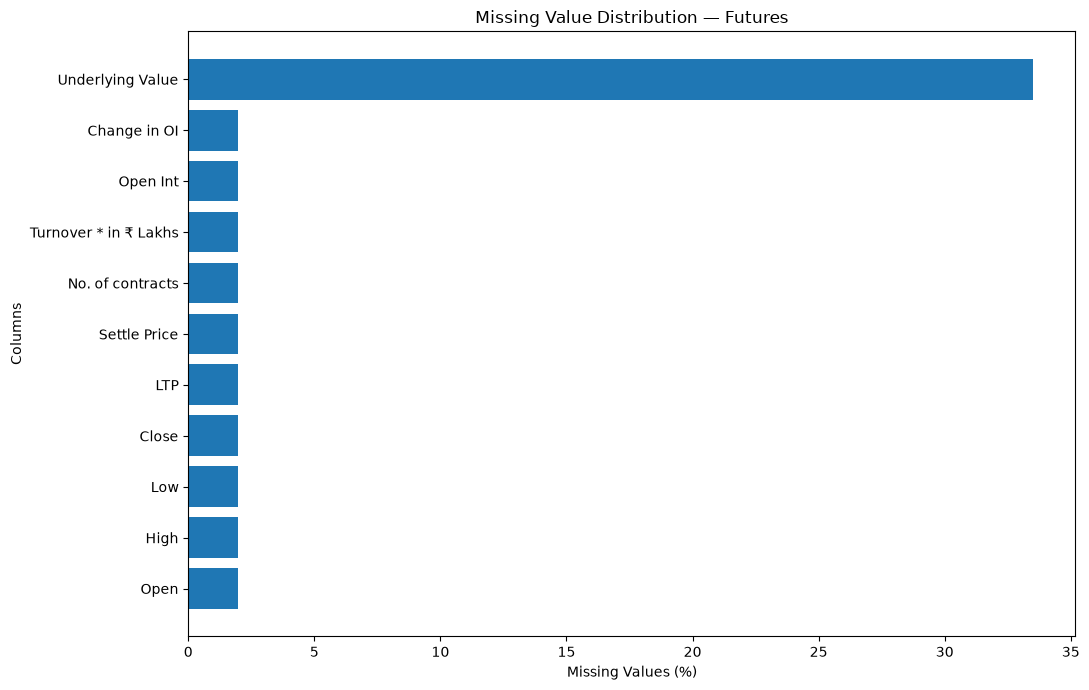

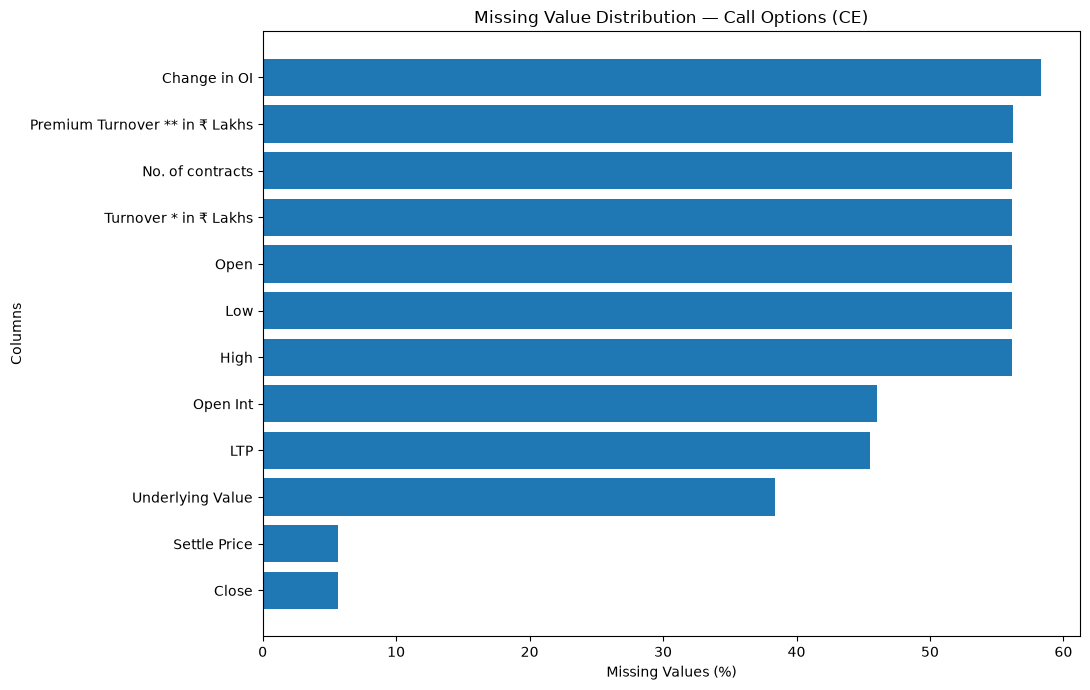

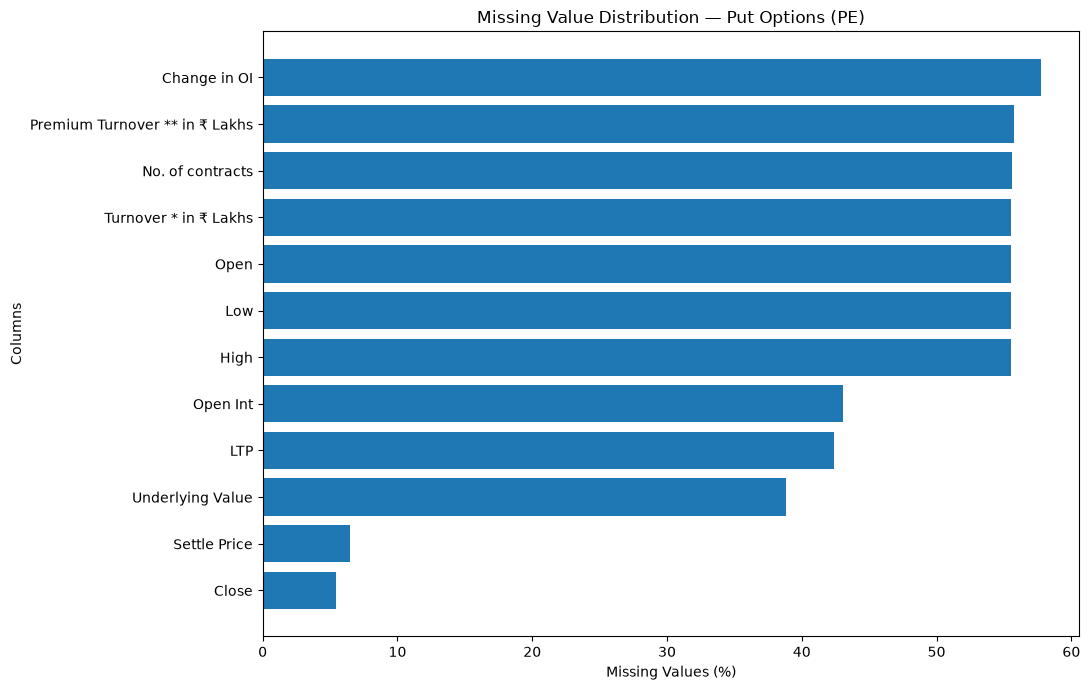

In [45]:
# ============================================
# 10.2 MISSING VALUE VISUALIZATION
# ============================================

for dataset_name in [
    "Futures",
    "Call Options (CE)",
    "Put Options (PE)"
]:

    subset = missing_analysis[
        (missing_analysis["Dataset"] == dataset_name)
        & (missing_analysis["Missing Percentage"] > 0)
    ].sort_values("Missing Percentage")

    plt.figure(figsize=(11, 7))

    plt.barh(
        subset["Column"],
        subset["Missing Percentage"]
    )

    plt.xlabel("Missing Values (%)")
    plt.ylabel("Columns")

    plt.title(
        f"Missing Value Distribution — {dataset_name}"
    )

    plt.tight_layout()
    plt.show()

### 11.1 Missing Value Treatment Report

This section categorizes missing values according to their potential impact on subsequent analysis.

Missing market variables are retained without automatic imputation. Missing identifiers and dates are flagged separately for further investigation.

No observations are deleted at this stage.

In [46]:
# ============================================
# 11.1 MISSING VALUE TREATMENT REPORT
# ============================================

identifier_candidates = [
    "Symbol",
    "Date",
    "Expiry",
    "Option type",
    "Strike Price"
]


def missing_treatment_report(df, dataset_name):

    results = []

    for column in df.columns:

        missing_count = df[column].isna().sum()

        if missing_count == 0:
            continue

        if column in identifier_candidates:
            category = "Identifier / Date"
            treatment = "Flag for investigation"

        elif column == "source_file":
            category = "Source metadata"
            treatment = "Investigate missing metadata"

        else:
            category = "Market variable"
            treatment = "Retain; no automatic imputation"

        results.append({
            "Dataset": dataset_name,
            "Column": column,
            "Missing Count": missing_count,
            "Missing Percentage": (
                missing_count / len(df) * 100
            ),
            "Category": category,
            "Proposed Treatment": treatment
        })

    return pd.DataFrame(results)


missing_treatment_summary = pd.concat(
    [
        missing_treatment_report(futures_clean, "Futures"),
        missing_treatment_report(calls_clean, "Call Options (CE)"),
        missing_treatment_report(puts_clean, "Put Options (PE)")
    ],
    ignore_index=True
)

display(missing_treatment_summary)

,Dataset,Column,Missing Count,Missing Percentage,Category,Proposed Treatment
0,Futures,Open,85,1.95,Market variable,Retain; no automatic imputation
1,Futures,High,85,1.95,Market variable,Retain; no automatic imputation
2,Futures,Low,85,1.95,Market variable,Retain; no automatic imputation
3,Futures,Close,85,1.95,Market variable,Retain; no automatic imputation
4,Futures,LTP,85,1.95,Market variable,Retain; no automatic imputation
5,Futures,Settle Price,85,1.95,Market variable,Retain; no automatic imputation
6,Futures,No. of contracts,85,1.95,Market variable,Retain; no automatic imputation
7,Futures,Turnover * in ₹ Lakhs,85,1.95,Market variable,Retain; no automatic imputation
8,Futures,Open Int,85,1.95,Market variable,Retain; no automatic imputation
9,Futures,Change in OI,86,1.98,Market variable,Retain; no automatic imputation


In [47]:
# ============================================
# 11.2 MISSING CRITICAL IDENTIFIERS
# ============================================

def check_missing_identifiers(df, dataset_name):

    columns = [
        col for col in identifier_candidates
        if col in df.columns
    ]

    print(f"\n{dataset_name}")
    print("=" * 55)

    for column in columns:

        count = df[column].isna().sum()

        print(f"{column}: {count:,} missing values")


check_missing_identifiers(futures_clean, "Futures")
check_missing_identifiers(calls_clean, "Call Options (CE)")
check_missing_identifiers(puts_clean, "Put Options (PE)")


Futures
Symbol: 0 missing values
Date: 0 missing values
Expiry: 0 missing values

Call Options (CE)
Symbol: 0 missing values
Date: 0 missing values
Expiry: 0 missing values
Option type: 0 missing values
Strike Price: 0 missing values

Put Options (PE)
Symbol: 0 missing values
Date: 0 missing values
Expiry: 0 missing values
Option type: 0 missing values
Strike Price: 0 missing values


## 12. Duplicate Record Investigation and Handling

Duplicate records can distort market statistics and lead to inaccurate conclusions.

This section identifies exact duplicate observations and repeated contract identifiers.

Exact duplicates are evaluated using all original dataset fields, excluding source-file metadata. Repeated contract identifiers are investigated separately because multiple records may share contract identifiers without being identical.

Only verified exact duplicates will be considered for removal. All removals will be documented.

In [48]:
# ============================================
# 12.1 EXACT DUPLICATE IDENTIFICATION
# ============================================

def identify_exact_duplicates(df, dataset_name):

    comparison_columns = [
        col for col in df.columns
        if col != "source_file"
    ]

    duplicate_mask = df.duplicated(
        subset=comparison_columns,
        keep="first"
    )

    duplicate_count = duplicate_mask.sum()

    print(f"\n{dataset_name}")
    print("Exact duplicate rows:", f"{duplicate_count:,}")

    return duplicate_mask


futures_exact_duplicates = identify_exact_duplicates(
    futures_clean, "Futures"
)

calls_exact_duplicates = identify_exact_duplicates(
    calls_clean, "Call Options (CE)"
)

puts_exact_duplicates = identify_exact_duplicates(
    puts_clean, "Put Options (PE)"
)


Futures
Exact duplicate rows: 54

Call Options (CE)
Exact duplicate rows: 57,226

Put Options (PE)
Exact duplicate rows: 57,673


In [49]:
# ============================================
# 12.2 REMOVE EXACT DUPLICATE ROWS
# ============================================

def remove_exact_duplicates(df, dataset_name):

    before = len(df)

    comparison_columns = [
        col for col in df.columns
        if col != "source_file"
    ]

    df = df.drop_duplicates(
        subset=comparison_columns,
        keep="first"
    ).copy()

    after = len(df)

    print(f"\n{dataset_name}")
    print(f"Records before: {before:,}")
    print(f"Records after:  {after:,}")
    print(f"Records removed: {before - after:,}")

    return df


futures_clean = remove_exact_duplicates(
    futures_clean, "Futures"
)

calls_clean = remove_exact_duplicates(
    calls_clean, "Call Options (CE)"
)

puts_clean = remove_exact_duplicates(
    puts_clean, "Put Options (PE)"
)


Futures
Records before: 4,348
Records after:  4,294
Records removed: 54



Call Options (CE)
Records before: 1,319,036
Records after:  1,261,810
Records removed: 57,226

Put Options (PE)
Records before: 1,358,362
Records after:  1,300,689
Records removed: 57,673


**Duplicate-removal decision:** Exact duplicates were identified by comparing all original data columns while excluding the source-file metadata. One occurrence of each identical observation was retained. Repeated contract identifiers with different market values were not automatically removed.

The source-file column was retained for the surviving observations to preserve provenance.

## 13. Post-Cleaning Validation

After numerical conversion, date standardization, missing-value assessment, and exact duplicate handling, the datasets are validated again.

This section verifies that the data types are correct, duplicate observations have been removed, and the original raw datasets remain unchanged.

In [50]:
# ============================================
# 13.1 POST-CLEANING VALIDATION
# ============================================

for name, raw_df, clean_df in [
    ("Futures", futures_raw, futures_clean),
    ("Call Options (CE)", calls_raw, calls_clean),
    ("Put Options (PE)", puts_raw, puts_clean)
]:

    comparison_columns = [
        col for col in clean_df.columns
        if col != "source_file"
    ]

    remaining_duplicates = clean_df.duplicated(
        subset=comparison_columns
    ).sum()

    print(f"\n{name}")
    print("=" * 60)

    print("Raw records:", f"{len(raw_df):,}")
    print("Processed records:", f"{len(clean_df):,}")
    print("Remaining exact duplicates:", remaining_duplicates)

    print(
        "Raw dataset unchanged:",
        raw_df.shape == (
            len(raw_df),
            len(raw_df.columns)
        )
    )


Futures
Raw records: 4,348
Processed records: 4,294
Remaining exact duplicates: 0
Raw dataset unchanged: True

Call Options (CE)
Raw records: 1,319,036
Processed records: 1,261,810
Remaining exact duplicates: 0
Raw dataset unchanged: True

Put Options (PE)
Raw records: 1,358,362
Processed records: 1,300,689
Remaining exact duplicates: 0
Raw dataset unchanged: True


## 14. Financial Data Validation

This section performs logical validation of financial variables after data type conversion and duplicate handling.

The validation examines OHLC price relationships, negative values, strike prices, and the consistency of trading and expiry dates.

Potentially inconsistent records are identified for investigation. They are not automatically deleted.

In [51]:
# ============================================
# 14.1 OHLC VALIDATION
# ============================================

def validate_ohlc(df, dataset_name):

    print(f"\n{dataset_name}")
    print("=" * 60)

    required_columns = ["Open", "High", "Low", "Close"]

    if not all(col in df.columns for col in required_columns):
        print("Complete OHLC columns not available.")
        return

    open_price = df["Open"]
    high_price = df["High"]
    low_price = df["Low"]
    close_price = df["Close"]

    complete_ohlc = (
        open_price.notna()
        & high_price.notna()
        & low_price.notna()
        & close_price.notna()
    )

    invalid_high_low = (
        complete_ohlc & (high_price < low_price)
    )

    invalid_high = (
        complete_ohlc
        & (high_price < open_price)
    ) | (
        complete_ohlc
        & (high_price < close_price)
    )

    invalid_low = (
        complete_ohlc
        & (low_price > open_price)
    ) | (
        complete_ohlc
        & (low_price > close_price)
    )

    print("Complete OHLC records:", f"{complete_ohlc.sum():,}")
    print("High below Low:", f"{invalid_high_low.sum():,}")
    print("High below Open or Close:", f"{invalid_high.sum():,}")
    print("Low above Open or Close:", f"{invalid_low.sum():,}")


validate_ohlc(futures_clean, "Futures")
validate_ohlc(calls_clean, "Call Options (CE)")
validate_ohlc(puts_clean, "Put Options (PE)")


Futures
Complete OHLC records: 4,263
High below Low: 0
High below Open or Close: 0
Low above Open or Close: 0

Call Options (CE)
Complete OHLC records: 578,243
High below Low: 0
High below Open or Close: 0
Low above Open or Close: 0

Put Options (PE)
Complete OHLC records: 603,757
High below Low: 0
High below Open or Close: 0
Low above Open or Close: 0


In [52]:
# ============================================
# 14.2 NEGATIVE VALUE VALIDATION
# ============================================

def validate_financial_values(df, dataset_name):

    print(f"\n{dataset_name}")
    print("=" * 60)

    for column in [
        "Open", "High", "Low", "Close",
        "LTP", "Settle Price", "Settlement Price"
    ]:

        if column in df.columns:

            count = (df[column] < 0).sum()

            print(f"Negative {column}: {count:,}")

    for column in [
        "No. of contracts",
        "Open Int",
        "Open Interest",
        "Turnover * in ₹ Lakhs",
        "Premium Turnover ** in ₹ Lakhs"
    ]:

        if column in df.columns:

            count = (df[column] < 0).sum()

            print(f"Negative {column}: {count:,}")

    if "Strike Price" in df.columns:

        invalid_strikes = (
            df["Strike Price"].notna()
            & (df["Strike Price"] <= 0)
        ).sum()

        print(f"Zero or negative strike prices: {invalid_strikes:,}")


validate_financial_values(futures_clean, "Futures")
validate_financial_values(calls_clean, "Call Options (CE)")
validate_financial_values(puts_clean, "Put Options (PE)")


Futures
Negative Open: 0
Negative High: 0
Negative Low: 0
Negative Close: 0
Negative LTP: 0
Negative Settle Price: 0
Negative No. of contracts: 0
Negative Open Int: 0
Negative Turnover * in ₹ Lakhs: 0

Call Options (CE)
Negative Open: 0
Negative High: 0
Negative Low: 0
Negative Close: 0
Negative LTP: 0
Negative Settle Price: 0
Negative No. of contracts: 0
Negative Open Int: 0
Negative Turnover * in ₹ Lakhs: 0
Negative Premium Turnover ** in ₹ Lakhs: 0
Zero or negative strike prices: 0

Put Options (PE)
Negative Open: 0
Negative High: 0
Negative Low: 0
Negative Close: 0
Negative LTP: 0
Negative Settle Price: 0
Negative No. of contracts: 0
Negative Open Int: 0
Negative Turnover * in ₹ Lakhs: 0
Negative Premium Turnover ** in ₹ Lakhs: 0
Zero or negative strike prices: 0


In [53]:
# ============================================
# 14.3 TRADING AND EXPIRY DATE VALIDATION
# ============================================

def validate_expiry_dates(df, dataset_name):

    print(f"\n{dataset_name}")
    print("=" * 60)

    if "Date" not in df.columns or "Expiry" not in df.columns:
        print("Required date columns not available.")
        return

    valid_dates = df["Date"].notna() & df["Expiry"].notna()

    invalid_expiry = (
        valid_dates & (df["Expiry"] < df["Date"])
    )

    print("Records with both dates available:", f"{valid_dates.sum():,}")
    print("Expiry earlier than trading date:", f"{invalid_expiry.sum():,}")


validate_expiry_dates(futures_clean, "Futures")
validate_expiry_dates(calls_clean, "Call Options (CE)")
validate_expiry_dates(puts_clean, "Put Options (PE)")


Futures
Records with both dates available: 4,294
Expiry earlier than trading date: 0

Call Options (CE)
Records with both dates available: 1,261,810
Expiry earlier than trading date: 0

Put Options (PE)
Records with both dates available: 1,300,689
Expiry earlier than trading date: 0


## 15. Final Preprocessing Summary

This section summarizes the preprocessing operations performed on the three datasets.

It compares the original and processed record counts, reports remaining missing values and duplicate observations, and provides an overview of the final dataset dimensions.

The summary supports transparency and reproducibility of the preprocessing workflow.

In [62]:
# ============================================
# 15. FINAL PREPROCESSING SUMMARY
# ============================================

final_summary = []

for name, raw_df, clean_df in [
    ("Futures", futures_raw, futures_clean),
    ("Call Options (CE)", calls_raw, calls_clean),
    ("Put Options (PE)", puts_raw, puts_clean)
]:

    comparison_columns = [
        col for col in clean_df.columns
        if col != "source_file"
    ]

    final_summary.append({

        "Dataset": name,

        "Original Records": len(raw_df),

        "Processed Records": len(clean_df),

        "Records Removed": len(raw_df) - len(clean_df),

        "Remaining Exact Duplicates": clean_df.duplicated(
            subset=comparison_columns
        ).sum(),

        "Missing Values": clean_df.isna().sum().sum(),

        "Total Columns": len(clean_df.columns),

        "Memory Usage (MB)": (
            clean_df.memory_usage(deep=True).sum()
            / (1024 ** 2)
        )
    })


final_summary_df = pd.DataFrame(final_summary)

display(
    final_summary_df.style.format({
        "Original Records": "{:,.0f}",
        "Processed Records": "{:,.0f}",
        "Records Removed": "{:,.0f}",
        "Remaining Exact Duplicates": "{:,.0f}",
        "Missing Values": "{:,.0f}",
        "Total Columns": "{:,.0f}",
        "Memory Usage (MB)": "{:.2f}"
    })
)

display(final_summary_df)

,Dataset,Original Records,Processed Records,Records Removed,Remaining Exact Duplicates,Missing Values,Total Columns,Memory Usage (MB)
0,Futures,"4,348","4,294",54,0,"1,714",15,0.74
1,Call Options (CE),"1,319,036","1,261,810","57,226",0,"6,394,331",18,256.77
2,Put Options (PE),"1,358,362","1,300,689","57,673",0,"6,475,222",18,264.68


,Dataset,Original Records,Processed Records,Records Removed,Remaining Exact Duplicates,Missing Values,Total Columns,Memory Usage (MB)
0,Futures,4348,4294,54,0,1714,15,0.74
1,Call Options (CE),1319036,1261810,57226,0,6394331,18,256.77
2,Put Options (PE),1358362,1300689,57673,0,6475222,18,264.68


In [55]:
# ============================================
# RESET INDEX AFTER DUPLICATE REMOVAL
# ============================================

futures_clean = futures_clean.reset_index(drop=True)
calls_clean = calls_clean.reset_index(drop=True)
puts_clean = puts_clean.reset_index(drop=True)

print("All DataFrame indices reset successfully.")

All DataFrame indices reset successfully.


## 16. Export Processed Datasets

The cleaned Futures, Call Options, and Put Options datasets are exported separately in Parquet format.

Parquet preserves numerical and datetime data types and provides efficient storage and retrieval for subsequent analysis.

The original NSE ZIP archives remain unchanged in data/raw.

In [56]:
# ============================================
# 16. EXPORT PROCESSED DATASETS
# ============================================

processed_files = {
    "Futures": PROCESSED_DATA_DIR / "futures_clean.parquet",
    "Call Options (CE)": PROCESSED_DATA_DIR / "calls_clean.parquet",
    "Put Options (PE)": PROCESSED_DATA_DIR / "puts_clean.parquet"
}

datasets_to_export = {
    "Futures": futures_clean,
    "Call Options (CE)": calls_clean,
    "Put Options (PE)": puts_clean
}

for name, df in datasets_to_export.items():

    output_path = processed_files[name]

    df.to_parquet(
        output_path,
        index=False,
        compression="snappy"
    )

    print(f"{name} exported successfully: {output_path.name}")

Futures exported successfully: futures_clean.parquet
Call Options (CE) exported successfully: calls_clean.parquet
Put Options (PE) exported successfully: puts_clean.parquet


In [59]:
# ============================================
# 17. VERIFY EXPORTED DATASETS
# ============================================

for name, path in processed_files.items():

    reloaded_df = pd.read_parquet(path)

    original_clean_df = datasets_to_export[name]

    print(f"\n{name}")
    print("=" * 60)

    print("File exists:", path.exists())
    print("Reloaded records:", f"{len(reloaded_df):,}")
    print("Original processed records:", f"{len(original_clean_df):,}")
    print("Dimensions match:", reloaded_df.shape == original_clean_df.shape)
    print("Column names match:", reloaded_df.columns.equals(original_clean_df.columns))

    assert reloaded_df.equals(original_clean_df), (
        f"Export verification failed for {name}"
    )

    print("Data integrity: PASSED")


Futures
File exists: True
Reloaded records: 4,294
Original processed records: 4,294
Dimensions match: True
Column names match: True
Data integrity: PASSED

Call Options (CE)
File exists: True
Reloaded records: 1,261,810
Original processed records: 1,261,810
Dimensions match: True
Column names match: True
Data integrity: PASSED

Put Options (PE)
File exists: True
Reloaded records: 1,300,689
Original processed records: 1,300,689
Dimensions match: True
Column names match: True
Data integrity: PASSED


## 18. Conclusion

This notebook completed the data cleaning and preprocessing stage for the NIFTY 50 Futures, Call Options, and Put Options datasets.

The original quarterly NSE datasets were loaded independently, and separate working copies were created to preserve the raw data.

The preprocessing operations included:

- Standardization of column-name whitespace.
- Conversion of financial variables into numerical data types.
- Conversion of trading and expiry dates into datetime format.
- Identification and assessment of missing values.
- Removal of exact duplicate observations.
- Validation of OHLC relationships and financial values.
- Verification of trading and expiry date consistency.
- Export of processed datasets in Parquet format.

A total of 114,953 exact duplicate observations were removed across the three datasets. The remaining datasets contained no exact duplicate rows.

Missing market values were retained rather than indiscriminately replaced with zero. This preserves the distinction between unavailable observations and genuine numerical zero values.

The final processed datasets were exported separately:

1. futures_clean.parquet
2. calls_clean.parquet
3. puts_clean.parquet

All three exported datasets were successfully reloaded and verified against their corresponding processed DataFrames.

The original raw datasets remain preserved separately.

The resulting datasets are ready for the next stage of the project: Exploratory Data Analysis, statistical investigation, and visualization.

The study period extends from January 2021 to 25 September 2026. September 2026 represents partial-month coverage and must be considered when interpreting monthly results.